# Implementación de operaciones de control óptico de un qubit con estados coherentes

## Modelo de Jaynes--Cummings resonante: $X$, $Y$, $\sqrt{X}$ y Hadamard

Este notebook extiende el análisis realizado previamente para la rotación $U_X$ y mantiene las mismas convenciones físicas y numéricas. El objetivo es estudiar, en el **régimen resonante** del modelo de Jaynes--Cummings, cómo la amplitud y la fase de un estado coherente pueden utilizarse para implementar operaciones de control sobre un qubit.

La descripción microscópica es

$$
H_I
=
\hbar g
\left(
a\sigma_+
+
a^\dagger\sigma_-
\right),
$$

obtenida en el marco de interacción, con

$$
\Delta=\omega_q-\omega_c=0,
$$

y bajo la **aproximación de onda rotante**.

El campo se prepara en

$$
|\alpha\rangle,
\qquad
\alpha=|\alpha|e^{-i\phi},
$$

y se expande en estados de Fock como

$$
|\alpha\rangle
=
e^{-|\alpha|^2/2}
\sum_{n=0}^{\infty}
\frac{\alpha^n}{\sqrt{n!}}|n\rangle.
$$

La distribución de fotones es de Poisson,

$$
P_n
=
e^{-|\alpha|^2}
\frac{|\alpha|^{2n}}{n!},
\qquad
\bar n=|\alpha|^2.
$$

Cada estado de Fock participa con una frecuencia de Rabi distinta,

$$
\Omega_n=2g\sqrt{n+1},
$$

por lo que la dinámica exacta puede generar entrelazamiento qubit--campo y desviarse de una rotación ideal.

En la aproximación semiclasica,

$$
a\rightarrow\alpha,
\qquad
a^\dagger\rightarrow\alpha^*,
$$

y se obtiene

$$
H_{\mathrm{sc}}
=
\hbar g|\alpha|
\left(
\cos\phi\,\sigma_x
+
\sin\phi\,\sigma_y
\right).
$$

La evolución ideal es

$$
\boxed{
R_\phi(\theta)
=
\exp
\left[
-\frac{i\theta}{2}
\left(
\cos\phi\,\sigma_x
+
\sin\phi\,\sigma_y
\right)
\right]
}
$$

con

$$
\boxed{
\theta=2g|\alpha|t.
}
$$

Por tanto,

$$
|\alpha|\rightarrow \text{escala de la velocidad de rotación},
$$

$$
\phi\rightarrow \text{eje de rotación en el plano }xy,
$$

$$
t\rightarrow \text{ángulo acumulado}.
$$

En este notebook se estudiarán

$$
X,\qquad Y,\qquad \sqrt X,\qquad H.
$$

Las tres primeras corresponden a un solo pulso resonante. Hadamard se tratará como una secuencia física de dos pulsos.

## 1. Convenciones y unidades

Trabajaremos con

$$
\hbar=1,
\qquad
g=1,
$$

de modo que el tiempo queda expresado en unidades de $1/g$.

Se conserva el orden tensorial

$$
\boxed{
\mathcal H
=
\mathcal H_{\mathrm{campo}}
\otimes
\mathcal H_{\mathrm{qubit}}.
}
$$

Para el qubit se adopta

$$
|e\rangle=\texttt{basis(2,0)},
\qquad
|g\rangle=\texttt{basis(2,1)},
$$

de manera que

$$
\sigma_z|e\rangle=+|e\rangle,
\qquad
\sigma_z|g\rangle=-|g\rangle.
$$

Como parámetros base utilizaremos

$$
g=1,
\qquad
|\alpha|=4,
\qquad
\bar n=16,
\qquad
N=50.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

print("Versión de QuTiP:", qt.__version__)

Versión de QuTiP: 5.3.1


In [2]:
# Parámetros generales
g = 1.0
alpha_abs = 4
N = 50
num_t = 500

# Campo
a_field = qt.destroy(N)
adag_field = a_field.dag()
n_field = adag_field * a_field

# Qubit
sx = qt.sigmax()
sy = qt.sigmay()
sz = qt.sigmaz()
sp = qt.sigmap()
sm = qt.sigmam()

Iq = qt.qeye(2)

ket_e = qt.basis(2, 0)
ket_g = qt.basis(2, 1)

print("<e|sigma_z|e> =", qt.expect(sz, ket_e))
print("<g|sigma_z|g> =", qt.expect(sz, ket_g))

<e|sigma_z|e> = 1.0
<g|sigma_z|g> = -1.0


## 2. Hamiltoniano en el regimen resonante 
En el marco de interacción,

$$
H_I(t)
=
g
\left(
a\sigma_+e^{i\Delta t}
+
a^\dagger\sigma_-e^{-i\Delta t}
\right).
$$

En resonancia,

$$
\Delta=0,
$$

por lo que

$$
\boxed{
H_{\mathrm{JC}}
=
g
\left(
a\sigma_+
+
a^\dagger\sigma_-
\right).
}
$$

La fase de control se incorpora en el estado coherente

$$
\alpha=|\alpha|e^{-i\phi},
$$


In [3]:
H_JC = g * (
    qt.tensor(a_field, sp)
    +
    qt.tensor(adag_field, sm)
)

print("dims =", H_JC.dims)
print("shape =", H_JC.shape)

dims = [[50, 2], [50, 2]]
shape = (100, 100)


## 3. Rotación semiclasica

Para

$$
\alpha=|\alpha|e^{-i\phi},
$$

se obtiene

$$
H_{\mathrm{sc}}
=
g|\alpha|
(\cos\phi\,\sigma_x+\sin\phi\,\sigma_y).
$$

Como

$$
(\cos\phi\,\sigma_x+\sin\phi\,\sigma_y)^2=I,
$$

la rotación ideal puede escribirse como

$$
R_\phi(\theta)
=
\cos\frac{\theta}{2}\,I
-
i\sin\frac{\theta}{2}
(\cos\phi\,\sigma_x+\sin\phi\,\sigma_y),
$$

donde

$$
\theta=2g|\alpha|t.
$$

En la base $\{|e\rangle,|g\rangle\}$,

$$
\boxed{
R_\phi(\theta)
=
\begin{pmatrix}
\cos(\theta/2)
&
-ie^{-i\phi}\sin(\theta/2)
\\
-ie^{i\phi}\sin(\theta/2)
&
\cos(\theta/2)
\end{pmatrix}.
}
$$

In [4]:
def R_phi(phi, theta):
    axis = np.cos(phi) * sx + np.sin(phi) * sy
    return (-1j * theta * axis / 2.0).expm()

def pulse_time(theta, alpha_abs=alpha_abs, g=g):
    return theta / (2.0 * g * alpha_abs)

## 4. Función general para un pulso resonante

Para un pulso caracterizado por $(\phi,\theta)$:

1. Se prepara

$$
|\alpha_\phi\rangle
=
\left||\alpha|e^{-i\phi}\right\rangle.
$$

2. El estado inicial conjunto es

$$
|\Psi(0)\rangle
=
|\alpha_\phi\rangle\otimes|\psi_q(0)\rangle.
$$

3. Se evoluciona con $H_{\mathrm{JC}}$.

4. Se obtiene el estado reducido

$$
\rho_q(t)
=
\operatorname{Tr}_{\mathrm{campo}}
\left[
|\Psi(t)\rangle\langle\Psi(t)|
\right].
$$

5. Se compara con

$$
|\psi_{\mathrm{id}}(t)\rangle
=
R_\phi[\theta(t)]|\psi_q(0)\rangle.
$$

La fidelidad para una entrada pura es

$$
\boxed{
F(t)
=
\langle\psi_{\mathrm{id}}(t)|
\rho_q(t)
|\psi_{\mathrm{id}}(t)\rangle.
}
$$

Esta cantidad es una fidelidad de estado para una entrada específica.

In [5]:
def simulate_single_pulse(phi, theta_target, psi_q0,
                          alpha_abs=alpha_abs, g=g, N=N, num_t=num_t):

    alpha = alpha_abs * np.exp(-1j * phi)
    psi_field = qt.coherent(N, alpha)
    psi0 = qt.tensor(psi_field, psi_q0)

    t_target = theta_target / (2.0 * g * alpha_abs)
    #t_target = 10
    tlist = np.linspace(0.0, t_target, num_t)
    theta_list = 2.0 * g * alpha_abs * tlist

    result = qt.sesolve(H_JC, psi0, tlist)

    rho_qubit = [state.ptrace(1) for state in result.states]

    bloch_x = np.array([qt.expect(sx, rho) for rho in rho_qubit])
    bloch_y = np.array([qt.expect(sy, rho) for rho in rho_qubit])
    bloch_z = np.array([qt.expect(sz, rho) for rho in rho_qubit])

    entropy = np.array([qt.entropy_vn(rho, base=2) for rho in rho_qubit])
    purity = np.array([rho.purity() for rho in rho_qubit])

    psi_ideal = [R_phi(phi, th) * psi_q0 for th in theta_list]

    fidelity = np.array([
        np.real(qt.expect(rho_qubit[k], psi_ideal[k]))
        for k in range(len(tlist))
    ])

    return {
        "phi": phi,
        "theta_target": theta_target,
        "t_target": t_target,
        "alpha": alpha,
        "tlist": tlist,
        "theta_list": theta_list,
        "rho_qubit": rho_qubit,
        "bloch_x": bloch_x,
        "bloch_y": bloch_y,
        "bloch_z": bloch_z,
        "entropy": entropy,
        "purity": purity,
        "fidelity": fidelity,
    }

## 5. Estados de entrada

Para no caracterizar las compuertas únicamente sobre $|g\rangle$, utilizaremos

$$
|g\rangle,
\qquad
|e\rangle,
$$

$$
|+\rangle
=
\frac{|g\rangle+|e\rangle}{\sqrt2},
$$

$$
|+_y\rangle
=
\frac{|g\rangle+i|e\rangle}{\sqrt2}.
$$

Los dos últimos estados son sensibles a las coherencias y a las fases relativas.

In [6]:
ket_plus = (ket_g + ket_e).unit()
ket_plus_y = (ket_g + 1j * ket_e).unit()

input_states = {
    "|g>": ket_g,
    "|e>": ket_e,
    "|+>": ket_plus,
    "|+_y>": ket_plus_y,
}

# Parte I. Compuerta $X$

Para

$$
\phi=0,
$$

se obtiene

$$
H_X=g|\alpha|\sigma_x,
$$

y

$$
R_x(\theta)=e^{-i\theta\sigma_x/2}.
$$

La compuerta $X$ corresponde a

$$
\theta_X=\pi,
$$

por lo que

$$
R_x(\pi)=-iX.
$$

El tiempo ideal es

$$
\boxed{
t_X=\frac{\pi}{2g|\alpha|}.
}
$$

Para $g=1$ y $|\alpha|=4$,

$$
t_X=\frac{\pi}{8}\simeq0.392699.
$$

Este caso debe reproducir el notebook original de $U_X$.

In [7]:
result_X_g = simulate_single_pulse(
    phi=0.0,
    theta_target=np.pi,
    psi_q0=ket_g
)

print("t_X =", result_X_g["t_target"])
print("F_X(|g>) =", result_X_g["fidelity"][-1])
print("S_q =", result_X_g["entropy"][-1])
print("Pureza =", result_X_g["purity"][-1])

t_X = 0.39269908169872414
F_X(|g>) = 0.9618800880753456
S_q = 0.22715740373377002
Pureza = 0.9292128707004803


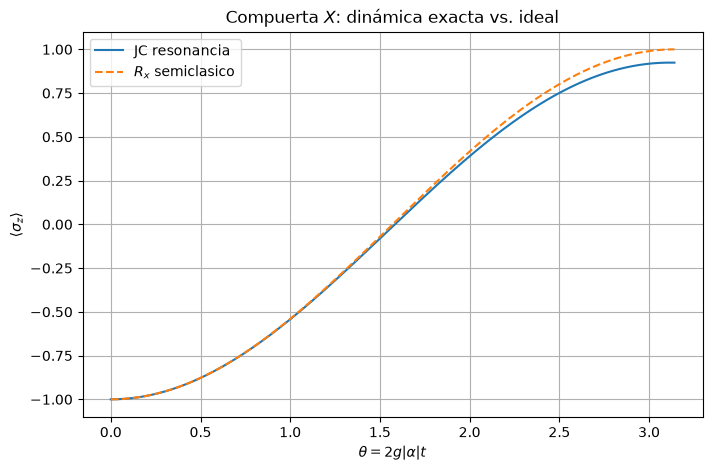

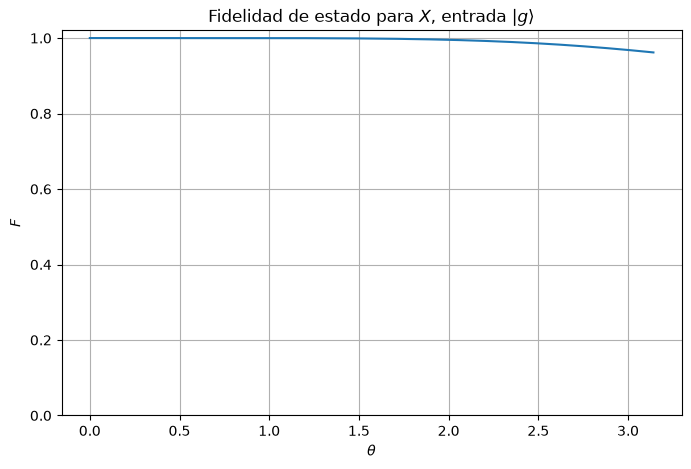

In [8]:
theta = result_X_g["theta_list"]

plt.figure(figsize=(8, 5))
plt.plot(theta, result_X_g["bloch_z"], label="JC resonancia")
plt.plot(theta, -np.cos(theta), "--", label=r"$R_x$ semiclasico")
plt.xlabel(r"$\theta=2g|\alpha|t$")
plt.ylabel(r"$\langle\sigma_z\rangle$")
plt.title(r"Compuerta $X$: dinámica exacta vs. ideal")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(theta, result_X_g["fidelity"])
plt.xlabel(r"$\theta$")
plt.ylabel(r"$F$")
plt.title(r"Fidelidad de estado para $X$, entrada $|g\rangle$")
plt.ylim(0, 1.02)
plt.grid()
plt.show()

$psi$ de forma analitica comprarla con la numerica, para X y Y

# Parte II. Compuerta $Y$

Para

$$
\phi=\frac{\pi}{2},
$$

la amplitud coherente es

$$
\alpha=-i|\alpha|,
$$

y

$$
H_Y=g|\alpha|\sigma_y.
$$

Por tanto,

$$
R_y(\theta)=e^{-i\theta\sigma_y/2}.
$$

Para

$$
\theta_Y=\pi,
$$

se obtiene

$$
R_y(\pi)=-iY.
$$

El tiempo es

$$
\boxed{
t_Y=\frac{\pi}{2g|\alpha|}=t_X.
}
$$

La diferencia entre $X$ y $Y$ reside en la fase óptica:

$$
\boxed{
\phi=0\Rightarrow x,
\qquad
\phi=\frac{\pi}{2}\Rightarrow y.
}
$$

In [9]:
result_Y_g = simulate_single_pulse(
    phi=np.pi / 2,
    theta_target=np.pi,
    psi_q0=ket_g
)

print("alpha_Y =", result_Y_g["alpha"])
print("t_Y =", result_Y_g["t_target"])
print("F_Y(|g>) =", result_Y_g["fidelity"][-1])
print("S_q =", result_Y_g["entropy"][-1])
print("Pureza =", result_Y_g["purity"][-1])

alpha_Y = (2.4492935982947064e-16-4j)
t_Y = 0.39269908169872414
F_Y(|g>) = 0.9618800880753458
S_q = 0.22715740373376841
Pureza = 0.9292128707004808


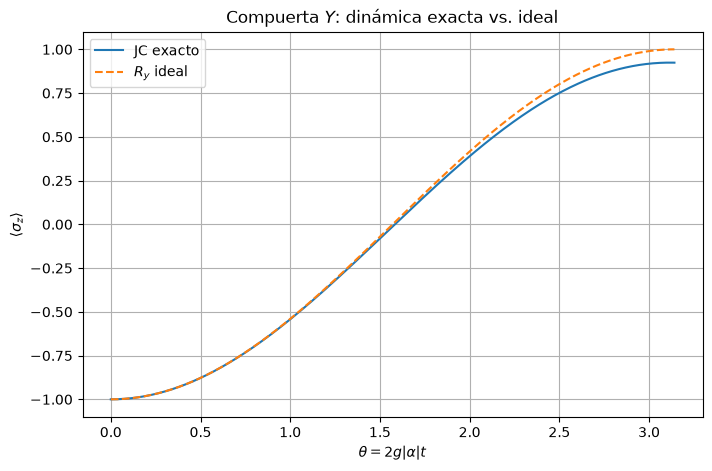

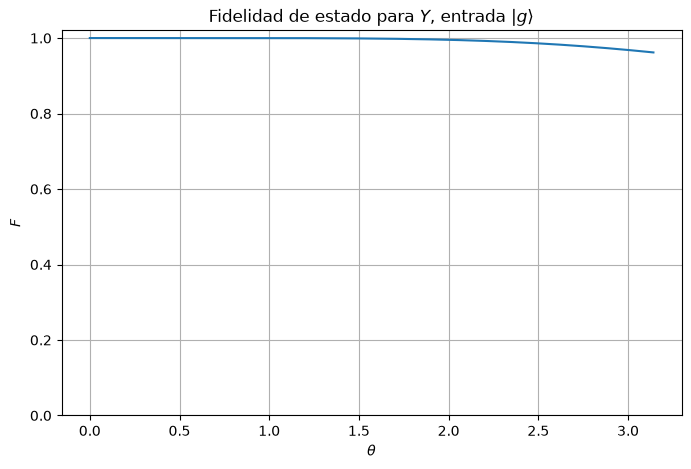

In [10]:
theta = result_Y_g["theta_list"]

plt.figure(figsize=(8, 5))
plt.plot(theta, result_Y_g["bloch_z"], label="JC exacto")
plt.plot(theta, -np.cos(theta), "--", label=r"$R_y$ ideal")
plt.xlabel(r"$\theta=2g|\alpha|t$")
plt.ylabel(r"$\langle\sigma_z\rangle$")
plt.title(r"Compuerta $Y$: dinámica exacta vs. ideal")
plt.grid()
plt.legend()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(theta, result_Y_g["fidelity"])
plt.xlabel(r"$\theta$")
plt.ylabel(r"$F$")
plt.title(r"Fidelidad de estado para $Y$, entrada $|g\rangle$")
plt.ylim(0, 1.02)
plt.grid()
plt.show()

## Comparación de las componentes del vector de Bloch para $X$ y $Y$

La comparación de únicamente

$$
\langle\sigma_z\rangle
$$

no permite distinguir una rotación alrededor del eje $x$ de una rotación alrededor del eje $y$ cuando el estado inicial es $|g\rangle$.

Para una rotación ideal alrededor de $x$,

$$
R_x(\theta)
=
e^{-i\theta\sigma_x/2},
$$

partiendo de

$$
|g\rangle,
$$

se obtiene

$$
\boxed{
\langle\sigma_x\rangle_X=0,
}
$$

$$
\boxed{
\langle\sigma_y\rangle_X=\sin\theta,
}
$$

$$
\boxed{
\langle\sigma_z\rangle_X=-\cos\theta.
}
$$

Por otro lado, para una rotación ideal alrededor de $y$,

$$
R_y(\theta)
=
e^{-i\theta\sigma_y/2},
$$

se obtiene

$$
\boxed{
\langle\sigma_x\rangle_Y=-\sin\theta,
}
$$

$$
\boxed{
\langle\sigma_y\rangle_Y=0,
}
$$

$$
\boxed{
\langle\sigma_z\rangle_Y=-\cos\theta.
}
$$

Por tanto, ambas rotaciones presentan la misma evolución de la componente $z$,

$$
\langle\sigma_z\rangle_X
=
\langle\sigma_z\rangle_Y
=
-\cos\theta,
$$

pero se diferencian en las componentes transversales.

Para $X$, la trayectoria ocurre idealmente en el plano $yz$:

$$
\mathbf r_X(\theta)
=
\left(
0,\,
\sin\theta,\,
-\cos\theta
\right).
$$

Para $Y$, la trayectoria ocurre idealmente en el plano $xz$:

$$
\mathbf r_Y(\theta)
=
\left(
-\sin\theta,\,
0,\,
-\cos\theta
\right).
$$

Esta comparación permite visualizar directamente el papel de la fase del
estado coherente:

$$
\boxed{
\phi=0
\longrightarrow
R_x
}
$$

y

$$
\boxed{
\phi=\frac{\pi}{2}
\longrightarrow
R_y.
}
$$

Es decir, la fase óptica $\phi$ determina el eje de rotación del qubit
dentro del plano $xy$.

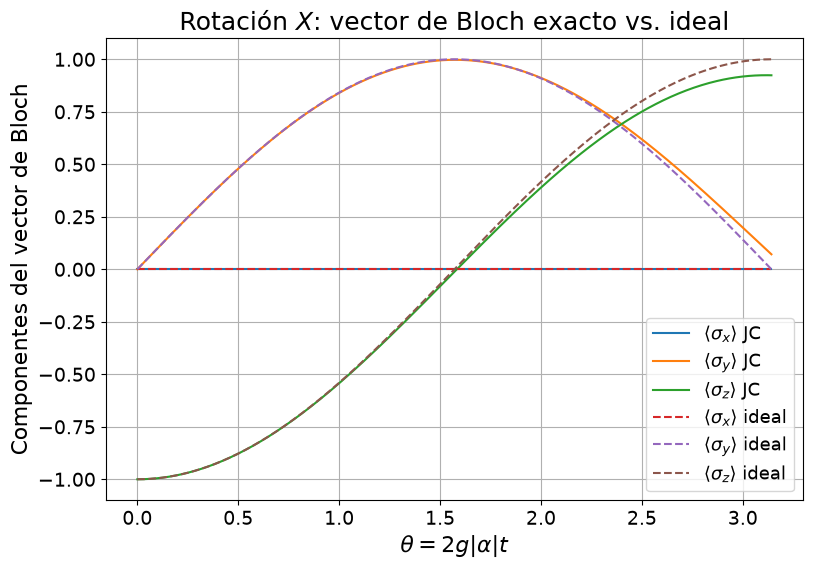

In [11]:
# ============================================================
# VECTOR DE BLOCH COMPLETO PARA LA COMPUERTA X
# ============================================================

theta_X = result_X_g["theta_list"]

# Componentes exactas obtenidas mediante JC
x_X_exact = result_X_g["bloch_x"]
y_X_exact = result_X_g["bloch_y"]
z_X_exact = result_X_g["bloch_z"]

# Componentes ideales para una rotación Rx(theta)
# partiendo del estado |g>
x_X_ideal = np.zeros_like(theta_X)
y_X_ideal = np.sin(theta_X)
z_X_ideal = -np.cos(theta_X)


plt.figure(figsize=(9, 6))

# Resultados exactos
plt.plot(
    theta_X,
    x_X_exact,
    label=r'$\langle\sigma_x\rangle$ JC'
)

plt.plot(
    theta_X,
    y_X_exact,
    label=r'$\langle\sigma_y\rangle$ JC'
)

plt.plot(
    theta_X,
    z_X_exact,
    label=r'$\langle\sigma_z\rangle$ JC'
)

# Resultados ideales
plt.plot(
    theta_X,
    x_X_ideal,
    '--',
    label=r'$\langle\sigma_x\rangle$ ideal'
)

plt.plot(
    theta_X,
    y_X_ideal,
    '--',
    label=r'$\langle\sigma_y\rangle$ ideal'
)

plt.plot(
    theta_X,
    z_X_ideal,
    '--',
    label=r'$\langle\sigma_z\rangle$ ideal'
)

plt.xlabel(
    r'$\theta=2g|\alpha|t$'
)

plt.ylabel(
    r'Componentes del vector de Bloch'
)

plt.title(
    r'Rotación $X$: vector de Bloch exacto vs. ideal',
     fontsize=18
)

# Etiquetas de los ejes
plt.xlabel(
    r'$\theta=2g|\alpha|t$',
    fontsize=16
)

plt.ylabel(
    r'Componentes del vector de Bloch',
    fontsize=16
)



# Tamaño de los números de los ejes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.ylim(-1.1, 1.1)

plt.grid()

# Tamaño de la leyenda
plt.legend(fontsize=13)

plt.show()


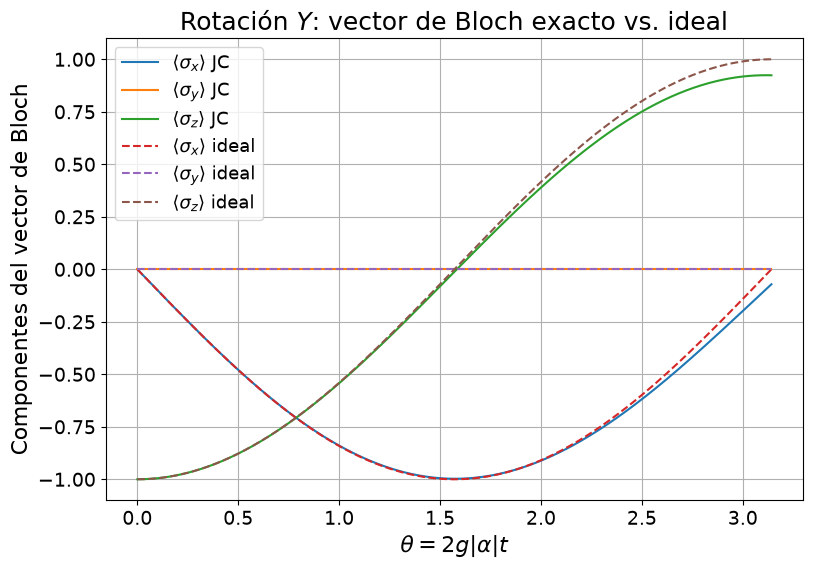

In [12]:
# ============================================================
# VECTOR DE BLOCH COMPLETO PARA LA COMPUERTA Y
# ============================================================

theta_Y = result_Y_g["theta_list"]

# Componentes exactas obtenidas mediante JC
x_Y_exact = result_Y_g["bloch_x"]
y_Y_exact = result_Y_g["bloch_y"]
z_Y_exact = result_Y_g["bloch_z"]

# Componentes ideales para una rotación Ry(theta)
# partiendo del estado |g>
x_Y_ideal = -np.sin(theta_Y)
y_Y_ideal = np.zeros_like(theta_Y)
z_Y_ideal = -np.cos(theta_Y)


plt.figure(figsize=(9, 6))

# Resultados exactos
plt.plot(
    theta_Y,
    x_Y_exact,
    label=r'$\langle\sigma_x\rangle$ JC'
)

plt.plot(
    theta_Y,
    y_Y_exact,
    label=r'$\langle\sigma_y\rangle$ JC'
)

plt.plot(
    theta_Y,
    z_Y_exact,
    label=r'$\langle\sigma_z\rangle$ JC'
)

# Resultados ideales
plt.plot(
    theta_Y,
    x_Y_ideal,
    '--',
    label=r'$\langle\sigma_x\rangle$ ideal'
)

plt.plot(
    theta_Y,
    y_Y_ideal,
    '--',
    label=r'$\langle\sigma_y\rangle$ ideal'
)

plt.plot(
    theta_Y,
    z_Y_ideal,
    '--',
    label=r'$\langle\sigma_z\rangle$ ideal'
)

# Etiquetas de los ejes
plt.xlabel(
    r'$\theta=2g|\alpha|t$',
    fontsize=16
)

plt.ylabel(
    r'Componentes del vector de Bloch',
    fontsize=16
)

# Título
plt.title(
    r'Rotación $Y$: vector de Bloch exacto vs. ideal',
    fontsize=18
)

# Tamaño de los números de los ejes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.ylim(-1.1, 1.1)

plt.grid()

# Tamaño de la leyenda
plt.legend(fontsize=13)

plt.show()

## Análisis de las trayectorias del vector de Bloch para las rotaciones $X$ y $Y$

Las gráficas anteriores permiten analizar no solamente la inversión de población del qubit, sino también la dirección de la trayectoria que describe su vector de Bloch durante la interacción con el campo coherente.

Para una entrada inicial

$$
|g\rangle,
$$

el vector de Bloch comienza en el polo sur de la esfera,

$$
\mathbf r(0)=(0,0,-1).
$$

### Rotación alrededor del eje $x$

Para la operación $X$ se utilizó una fase del estado coherente

$$
\phi=0.
$$

En la aproximación semiclásica, el Hamiltoniano efectivo es

$$
H_X=g|\alpha|\sigma_x,
$$

por lo que la evolución ideal corresponde a

$$
R_x(\theta)=e^{-i\theta\sigma_x/2}.
$$

Partiendo de $|g\rangle$, las componentes ideales del vector de Bloch son

$$
\langle\sigma_x\rangle_{\mathrm{id}}=0,
$$

$$
\langle\sigma_y\rangle_{\mathrm{id}}=\sin\theta,
$$

$$
\langle\sigma_z\rangle_{\mathrm{id}}=-\cos\theta.
$$

Por tanto,

$$
\boxed{
\mathbf r_X(\theta)=
\left(
0,\,
\sin\theta,\,
-\cos\theta
\right).
}
$$

La simulación exacta del modelo de Jaynes--Cummings reproduce estrechamente esta trayectoria. La componente

$$
\langle\sigma_x\rangle
$$

permanece prácticamente nula durante toda la evolución, mientras que las componentes

$$
\langle\sigma_y\rangle
\qquad\text{y}\qquad
\langle\sigma_z\rangle
$$

describen la rotación. Esto indica que la trayectoria se encuentra predominantemente en el plano $yz$, como corresponde a una rotación alrededor del eje $x$.

En los primeros tiempos de interacción, la dinámica exacta y la rotación ideal son prácticamente indistinguibles. Sin embargo, al aproximarse a

$$
\theta=\pi,
$$

comienzan a observarse pequeñas diferencias. Idealmente,

$$
\mathbf r_X(\pi)=(0,0,1),
$$

mientras que la evolución exacta no alcanza exactamente el polo norte de la esfera de Bloch.

Esta desviación es consistente con la fidelidad de estado obtenida para la entrada $|g\rangle$,

$$
F_X\simeq0.96188,
$$

así como con la pureza

$$
\mathcal P_q\simeq0.92921.
$$

Por tanto, la dinámica exacta reproduce con buena aproximación la rotación $X_\pi$, aunque el estado final del qubit no coincide exactamente con el resultado unitario ideal.

---

### Rotación alrededor del eje $y$

Para implementar la operación $Y$ se modificó únicamente la fase del estado coherente a

$$
\phi=\frac{\pi}{2}.
$$

La amplitud coherente es entonces

$$
\alpha
=
|\alpha|e^{-i\pi/2}
=
-i|\alpha|,
$$

y el Hamiltoniano semiclásico toma la forma

$$
H_Y=g|\alpha|\sigma_y.
$$

La evolución ideal es

$$
R_y(\theta)=e^{-i\theta\sigma_y/2}.
$$

Para el mismo estado inicial $|g\rangle$, las componentes ideales del vector de Bloch son ahora

$$
\langle\sigma_x\rangle_{\mathrm{id}}
=
-\sin\theta,
$$

$$
\langle\sigma_y\rangle_{\mathrm{id}}
=
0,
$$

$$
\langle\sigma_z\rangle_{\mathrm{id}}
=
-\cos\theta.
$$

Por tanto,

$$
\boxed{
\mathbf r_Y(\theta)=
\left(
-\sin\theta,\,
0,\,
-\cos\theta
\right).
}
$$

En este caso, la simulación exacta muestra que

$$
\langle\sigma_y\rangle\simeq0,
$$

mientras que las componentes

$$
\langle\sigma_x\rangle
\qquad\text{y}\qquad
\langle\sigma_z\rangle
$$

son las que evolucionan.

La trayectoria se encuentra entonces predominantemente en el plano $xz$, característica de una rotación alrededor del eje $y$.

Nuevamente, la dinámica exacta reproduce muy bien la evolución ideal durante la mayor parte del pulso y las principales diferencias aparecen al aproximarse a

$$
\theta=\pi.
$$

Para esta operación se obtuvo

$$
F_Y\simeq0.96188,
$$

junto con

$$
S_q\simeq0.22716,
\qquad
\mathcal P_q\simeq0.92921.
$$

Estos valores coinciden, dentro de la precisión numérica, con los obtenidos para la rotación $X$.

---

## Comparación entre $R_x$ y $R_y$: efecto de la fase óptica

La tercera gráfica permite observar de manera particularmente clara la función de la fase $\phi$ del estado coherente.

Para

$$
\phi=0,
$$

la componente transversal que evoluciona es

$$
\langle\sigma_y\rangle_X
\simeq
\sin\theta,
$$

mientras que para

$$
\phi=\frac{\pi}{2},
$$

la componente transversal es

$$
\langle\sigma_x\rangle_Y
\simeq
-\sin\theta.
$$

En consecuencia,

$$
\boxed{
\langle\sigma_y\rangle_X
\simeq
-\langle\sigma_x\rangle_Y.
}
$$

Este comportamiento muestra que ambas evoluciones poseen prácticamente la misma magnitud, pero se realizan en planos distintos de la esfera de Bloch.

La componente $z$ no permite por sí sola distinguir las dos rotaciones, ya que idealmente

$$
\boxed{
\langle\sigma_z\rangle_X
=
\langle\sigma_z\rangle_Y
=
-\cos\theta.
}
$$

Por esta razón, observar únicamente la inversión de población podría hacer que las dinámicas de $X$ y $Y$ parecieran iguales. La diferencia física se manifiesta en las componentes transversales del vector de Bloch.

Los resultados confirman así la relación

$$
\boxed{
\phi=0
\longrightarrow
R_x,
}
$$

$$
\boxed{
\phi=\frac{\pi}{2}
\longrightarrow
R_y.
}
$$

Por tanto, la fase del estado coherente actúa como un parámetro de control del eje de rotación del qubit dentro del plano $xy$,

$$
\boxed{
\phi
\longrightarrow
\text{eje de rotación}.
}
$$

---

## Interpretación de las desviaciones respecto de la dinámica ideal

Las pequeñas diferencias observadas entre las curvas exactas y las curvas semiclásicas aumentan conforme avanza la interacción.

Estas desviaciones se originan en que el campo utilizado en la simulación exacta no es un campo clásico, sino un estado coherente con un número medio finito de fotones,

$$
\bar n=|\alpha|^2=16.
$$

El estado coherente contiene una distribución de estados de Fock,

$$
|\alpha\rangle
=
e^{-|\alpha|^2/2}
\sum_{n=0}^{\infty}
\frac{\alpha^n}{\sqrt{n!}}
|n\rangle,
$$

y los diferentes estados de Fock participan en la dinámica de Jaynes--Cummings con frecuencias de Rabi dependientes de $n$,

$$
\Omega_n=2g\sqrt{n+1}.
$$

Por ello, las diferentes contribuciones del campo acumulan fases ligeramente distintas durante la evolución. Como consecuencia, la dinámica exacta del qubit comienza a separarse de la rotación semiclásica ideal.

De manera simultánea, la interacción genera correlaciones entre el qubit y el campo. Esto es consistente con los valores encontrados de

$$
S_q>0
$$

y

$$
\mathcal P_q<1.
$$

Así, la desviación respecto de la rotación ideal y la pérdida de pureza del estado reducido del qubit tienen un origen común en la naturaleza cuántica del campo coherente.

---

## Conclusión

Las trayectorias del vector de Bloch confirman que el modelo de Jaynes--Cummings resonante con un campo inicialmente preparado en un estado coherente reproduce con buena aproximación las rotaciones semiclasicas esperadas.

Para una amplitud fija

$$
|\alpha|=4,
$$

el cambio de la fase del campo de

$$
\phi=0
$$

a

$$
\phi=\frac{\pi}{2}
$$

transforma la dinámica de una rotación alrededor de $x$ en una rotación alrededor de $y$, sin modificar de manera apreciable la fidelidad, la entropía o la pureza obtenidas para la entrada $|g\rangle$.

Los resultados proporcionan evidencia numérica de que la fase óptica puede utilizarse para seleccionar el eje de control del qubit,

$$
\boxed{
\phi
\longrightarrow
\text{eje de rotación en el plano }xy,
}
$$

mientras que las pequeñas desviaciones respecto del comportamiento unitario ideal reflejan la naturaleza cuántica del campo coherente y el entrelazamiento generado durante la interacción.

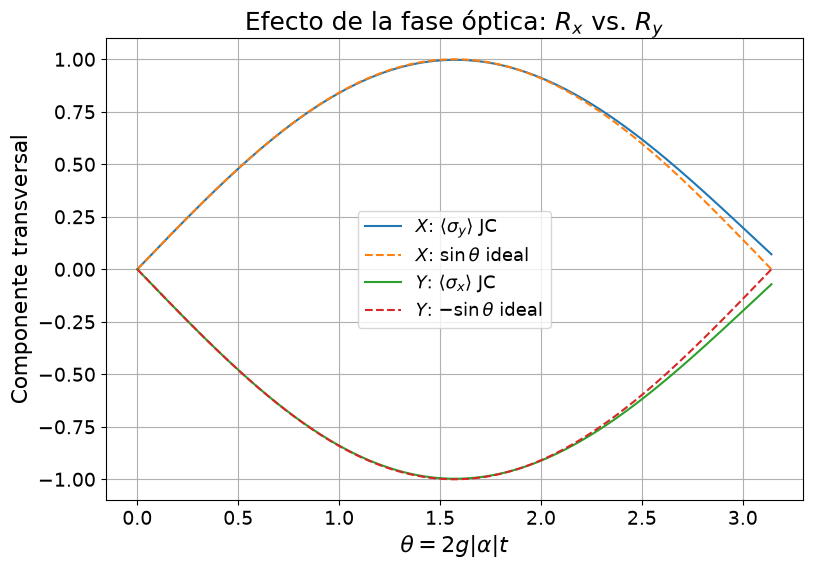

In [13]:
# ============================================================
# COMPARACIÓN DIRECTA X VS Y
# ============================================================

plt.figure(figsize=(9, 6))

# Para Rx, la componente transversal característica es sigma_y
plt.plot(
    theta_X,
    result_X_g["bloch_y"],
    label=r'$X$: $\langle\sigma_y\rangle$ JC'
)

plt.plot(
    theta_X,
    np.sin(theta_X),
    '--',
    label=r'$X$: $\sin\theta$ ideal'
)

# Para Ry, la componente transversal característica es sigma_x
plt.plot(
    theta_Y,
    result_Y_g["bloch_x"],
    label=r'$Y$: $\langle\sigma_x\rangle$ JC'
)

plt.plot(
    theta_Y,
    -np.sin(theta_Y),
    '--',
    label=r'$Y$: $-\sin\theta$ ideal'
)

plt.xlabel(
    r'$\theta=2g|\alpha|t$',
    fontsize=16
)

plt.ylabel(
    r'Componente transversal',
    fontsize=16
)

plt.title(
    r'Efecto de la fase óptica: $R_x$ vs. $R_y$',
    fontsize=18
)


# Tamaño de los números de los ejes
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.ylim(-1.1, 1.1)

plt.grid()

# Tamaño de la leyenda
plt.legend(fontsize=13)

plt.show()

# Parte III. Compuerta $\sqrt X$

Se tiene

$$
R_x\left(\frac{\pi}{2}\right)
=
\frac{1}{\sqrt2}(I-iX),
$$

y la compuerta convencional satisface

$$
\boxed{
\sqrt X
=
e^{i\pi/4}
R_x\left(\frac{\pi}{2}\right).
}
$$

Además,

$$
\left[
R_x\left(\frac{\pi}{2}\right)
\right]^2
=
R_x(\pi)
=
-iX.
$$

Para esta operación,

$$
\phi=0,
\qquad
\theta_{\sqrt X}=\frac{\pi}{2},
$$

y

$$
\boxed{
t_{\sqrt X}
=
\frac{\pi}{4g|\alpha|}.
}
$$

Con $g=1$ y $|\alpha|=4$,

$$
t_{\sqrt X}
=
\frac{\pi}{16}
\simeq0.19635.
$$

In [14]:
result_sqrtX_g = simulate_single_pulse(
    phi=0.0,
    theta_target=np.pi / 2,
    psi_q0=ket_g
)

print("t_sqrtX =", result_sqrtX_g["t_target"])
print("F_sqrtX(|g>) =", result_sqrtX_g["fidelity"][-1])
print("S_q =", result_sqrtX_g["entropy"][-1])
print("Pureza =", result_sqrtX_g["purity"][-1])

t_sqrtX = 0.19634954084936207
F_sqrtX(|g>) = 0.9987169410827419
S_q = 0.013815370827298305
Pureza = 0.9975117488506894


## Análisis de la operación $\sqrt{X}$

Para implementar la operación $\sqrt{X}$ se mantiene la fase del estado coherente en

$$
\phi=0,
$$

por lo que el eje de rotación continúa siendo el eje $x$. Sin embargo, el ángulo se reduce a

$$
\theta_{\sqrt X}=\frac{\pi}{2}.
$$

De la relación

$$
\theta=2g|\alpha|t
$$

se obtiene

$$
t_{\sqrt X}
=
\frac{\pi}{4g|\alpha|}.
$$

Para los parámetros

$$
g=1,
\qquad
|\alpha|=4,
$$

el tiempo de interacción es

$$
\boxed{
t_{\sqrt X}
=
0.19634954.
}
$$

La simulación exacta del modelo de Jaynes--Cummings produce, para una entrada inicial $|g\rangle$,

$$
\boxed{
F_{\sqrt X}(|g\rangle)
=
0.99871694,
}
$$

lo que corresponde aproximadamente a una fidelidad de estado del

$$
\boxed{
99.87\%.
}
$$

Este valor es considerablemente mayor que el obtenido para las rotaciones completas $X_\pi$ y $Y_\pi$, para las cuales se encontró una fidelidad cercana al $96.19\%$.

La diferencia puede relacionarse con la menor duración del pulso. En efecto,

$$
t_{\sqrt X}
=
\frac{1}{2}t_X.
$$

Durante este intervalo más corto, las distintas contribuciones de los estados de Fock presentes en el estado coherente tienen menos tiempo para acumular fases diferentes. Por tanto, la dinámica exacta permanece más próxima a la evolución semiclasica ideal.

Esta interpretación también es consistente con la entropía de von Neumann obtenida,

$$
\boxed{
S_q
=
0.0138154,
}
$$

que es muy cercana a cero, y con la pureza

$$
\boxed{
\mathcal P_q
=
0.9975117.
}
$$

La longitud correspondiente del vector de Bloch es

$$
|\mathbf r|
=
\sqrt{2\mathcal P_q-1}
\simeq
0.9975,
$$

muy próxima al valor unitario esperado para un estado puro.

Para una entrada $|g\rangle$, la rotación ideal satisface

$$
R_x\left(\frac{\pi}{2}\right)|g\rangle
=
\frac{1}{\sqrt2}
\left(
|g\rangle-i|e\rangle
\right),
$$

por lo que el vector de Bloch ideal al final de la operación es

$$
\boxed{
\mathbf r_{\sqrt X}^{\mathrm{ideal}}
=
(0,1,0).
}
$$

Por tanto, a diferencia de la operación $X_\pi$, que lleva idealmente el estado desde el polo sur hasta el polo norte de la esfera de Bloch, la operación $\sqrt X$ lleva el qubit hasta el ecuador.

Los resultados muestran que, manteniendo fijo el eje de rotación mediante

$$
\phi=0,
$$

el ángulo puede controlarse mediante el tiempo de interacción:

$$
\boxed{
t
\longrightarrow
\theta.
}
$$

En conjunto con los resultados obtenidos para $X$ y $Y$, se obtiene la relación de control

$$
\boxed{
\phi
\longrightarrow
\text{eje de rotación},
\qquad
t
\longrightarrow
\text{ángulo de rotación}.
}
$$

Además, la elevada fidelidad y la pequeña generación de entrelazamiento observadas para $\sqrt X$ muestran que, para los parámetros considerados, una interacción resonante de menor duración reproduce con gran precisión la rotación semiclasica esperada.

## 6. Fidelidades de estado para varias entradas

Para cada compuerta de un solo pulso calcularemos

$$
F_g,\qquad F_e,\qquad F_+,\qquad F_{+_y}.
$$

Esto permitirá verificar si el desempeño depende del estado inicial y evitará identificar una buena transformación de $|g\rangle$ con una buena compuerta completa.

In [15]:
def final_state_fidelity_single_pulse(phi, theta_target, psi_q0,
                                      alpha_abs=alpha_abs, g=g, N=N):

    alpha = alpha_abs * np.exp(-1j * phi)
    psi_field = qt.coherent(N, alpha)
    psi0 = qt.tensor(psi_field, psi_q0)

    t_target = theta_target / (2.0 * g * alpha_abs)
    U = (-1j * H_JC * t_target).expm()

    psi_final = U * psi0
    rho_q = psi_final.ptrace(1)

    psi_target = R_phi(phi, theta_target) * psi_q0
    F = float(np.real(qt.expect(rho_q, psi_target)))

    return F, rho_q


single_pulse_gates = {
    "X": (0.0, np.pi),
    "Y": (np.pi / 2, np.pi),
    "sqrt(X)": (0.0, np.pi / 2),
}

state_fidelity_table = {}

for gate_name, (phi_gate, theta_gate) in single_pulse_gates.items():
    state_fidelity_table[gate_name] = {}

    for state_name, psi0_q in input_states.items():
        F_state, _ = final_state_fidelity_single_pulse(
            phi_gate, theta_gate, psi0_q
        )
        state_fidelity_table[gate_name][state_name] = F_state

for gate_name, values in state_fidelity_table.items():
    print("\n", gate_name)
    for state_name, F_state in values.items():
        print("   ", state_name, ":", F_state)


 X
    |g> : 0.9618802369700965
    |e> : 0.9630301111912392
    |+> : 0.9841387902055131
    |+_y> : 0.9950100102796982

 Y
    |g> : 0.961880236970098
    |e> : 0.9630301111912398
    |+> : 0.9950100102796995
    |+_y> : 0.984138790205514

 sqrt(X)
    |g> : 0.9987169469770298
    |e> : 0.9744729067001379
    |+> : 0.992202477006582
    |+_y> : 0.9986859396679532


# Parte IV. Compuerta Hadamard

La compuerta Hadamard es

$$
H
=
\frac{1}{\sqrt2}
\begin{pmatrix}
1&1\\
1&-1
\end{pmatrix}.
$$

Dentro del conjunto de rotaciones resonantes accesibles,

$$
\boxed{
R_x(\pi)
R_y\left(\frac{\pi}{2}\right)
=
-iH.
}
$$

El orden temporal es

$$
\boxed{
R_y\left(\frac{\pi}{2}\right)
\longrightarrow
R_x(\pi).
}
$$

Primer pulso:

$$
\phi_1=\frac{\pi}{2},
\qquad
\theta_1=\frac{\pi}{2},
\qquad
t_1=\frac{\pi}{4g|\alpha|}.
$$

Segundo pulso:

$$
\phi_2=0,
\qquad
\theta_2=\pi,
\qquad
t_2=\frac{\pi}{2g|\alpha|}.
$$

Por tanto,

$$
t_H
=
t_1+t_2
=
\frac{3\pi}{4g|\alpha|}.
$$

## Protocolo físico usado aquí

La igualdad matricial anterior es una construcción semiclasica. En la dinámica JC exacta, el primer pulso puede dejar al qubit correlacionado con el campo.

Por ello, en esta primera simulación utilizaremos un protocolo explícito:

$$
\boxed{
\text{cada rotación elemental utiliza un estado coherente nuevo}.
}
$$

Es decir,

$$
\rho_q
\stackrel{\mathcal E_{Y_{\pi/2}}}{\longrightarrow}
\rho_1
\stackrel{\mathcal E_X}{\longrightarrow}
\rho_H.
$$

La transformación física total será

$$
\boxed{
\mathcal E_H
=
\mathcal E_X
\circ
\mathcal E_{Y_{\pi/2}}.
}
$$

## 7. Operadores de Kraus del pulso exacto

Para un campo inicialmente puro $|\alpha\rangle$, el JC exacto induce sobre el qubit el canal

$$
\mathcal E(\rho_q)
=
\operatorname{Tr}_f
\left[
U_{\mathrm{JC}}
\left(
|\alpha\rangle\langle\alpha|
\otimes
\rho_q
\right)
U_{\mathrm{JC}}^\dagger
\right].
$$

Puede escribirse como

$$
\mathcal E(\rho_q)
=
\sum_nK_n\rho_qK_n^\dagger,
$$

con

$$
\boxed{
K_n
=
\langle n|
U_{\mathrm{JC}}
|\alpha\rangle.
}
$$

La completez requiere

$$
\sum_nK_n^\dagger K_n
\simeq
I.
$$

Esta forma permite aplicar el pulso a estados mixtos y componer varios pulsos físicos.

In [16]:
def kraus_operators_single_pulse(phi, theta_target,
                                 alpha_abs=alpha_abs, g=g, N=N):

    alpha = alpha_abs * np.exp(-1j * phi)
    psi_field = qt.coherent(N, alpha)

    t_target = theta_target / (2.0 * g * alpha_abs)
    U = (-1j * H_JC * t_target).expm()

    U_matrix = U.full()
    c_alpha = psi_field.full().ravel()

    K_list = []

    for n_out in range(N):
        K = np.zeros((2, 2), dtype=complex)

        for q_out in range(2):
            for q_in in range(2):
                value = 0.0 + 0.0j

                for n_in in range(N):
                    row = 2 * n_out + q_out
                    col = 2 * n_in + q_in
                    value += U_matrix[row, col] * c_alpha[n_in]

                K[q_out, q_in] = value

        K_list.append(
            qt.Qobj(K, dims=[[2], [2]])
        )

    return K_list


def apply_kraus_channel(rho_q, K_list):
    rho_out = 0 * rho_q

    for K in K_list:
        rho_out += K * rho_q * K.dag()

    return rho_out


def check_kraus_completeness(K_list):
    total = 0 * Iq

    for K in K_list:
        total += K.dag() * K

    return total

In [17]:
K_Y_half = kraus_operators_single_pulse(
    phi=np.pi / 2,
    theta_target=np.pi / 2
)

K_X_pi = kraus_operators_single_pulse(
    phi=0.0,
    theta_target=np.pi
)

H_gate = (1 / np.sqrt(2)) * qt.Qobj(
    np.array([
        [1,  1],
        [1, -1]
    ], dtype=complex),
    dims=[[2], [2]]
)

def hadamard_fresh_fields(rho_q):
    rho_after_Y = apply_kraus_channel(rho_q, K_Y_half)
    rho_after_H = apply_kraus_channel(rho_after_Y, K_X_pi)
    return rho_after_Y, rho_after_H

In [18]:
hadamard_state_fidelity = {}

for state_name, psi_q0 in input_states.items():

    rho_q0 = qt.ket2dm(psi_q0)
    _, rho_after_H = hadamard_fresh_fields(rho_q0)

    psi_target = H_gate * psi_q0

    F_H = float(
        np.real(
            qt.expect(rho_after_H, psi_target)
        )
    )

    hadamard_state_fidelity[state_name] = F_H

print("FIDELIDADES DE ESTADO PARA HADAMARD")

for state_name, F_H in hadamard_state_fidelity.items():
    print(state_name, ":", F_H)

FIDELIDADES DE ESTADO PARA HADAMARD
|g> : 0.9828964387288938
|e> : 0.9594214780701975
|+> : 0.9606648489708793
|+_y> : 0.9877467727651373


# 8. Fidelidad promedio de compuerta

Para caracterizar una compuerta independientemente de una entrada particular utilizaremos la fidelidad promedio de compuerta.

Sea

$$
|\Phi\rangle
=
\frac{|00\rangle+|11\rangle}{\sqrt2}.
$$

Aplicamos el canal físico a la segunda mitad:

$$
\rho_{\mathcal E}
=
(I\otimes\mathcal E)
\left(
|\Phi\rangle\langle\Phi|
\right).
$$

Para una compuerta ideal $U$,

$$
|\Phi_U\rangle
=
(I\otimes U)|\Phi\rangle.
$$

La fidelidad de entrelazamiento es

$$
F_e
=
\langle\Phi_U|
\rho_{\mathcal E}
|\Phi_U\rangle.
$$

Para un qubit,

$$
\boxed{
F_{\mathrm{avg}}
=
\frac{2F_e+1}{3}.
}
$$

Esta cantidad es más adecuada que una fidelidad obtenida únicamente para $|g\rangle$ cuando se desea hablar de la calidad global de una operación.

In [19]:
ket0_aux = qt.basis(2, 0)
ket1_aux = qt.basis(2, 1)
I_aux = qt.qeye(2)

phi_plus = (
    qt.tensor(ket0_aux, ket_e)
    +
    qt.tensor(ket1_aux, ket_g)
).unit()

rho_phi = qt.ket2dm(phi_plus)


def apply_channel_to_second_subsystem(rho_AQ, K_list):
    rho_out = 0 * rho_AQ

    for K in K_list:
        K_total = qt.tensor(I_aux, K)
        rho_out += K_total * rho_AQ * K_total.dag()

    return rho_out


def average_gate_fidelity_from_kraus(K_list, U_target):
    rho_out = apply_channel_to_second_subsystem(rho_phi, K_list)

    U_total = qt.tensor(I_aux, U_target)
    phi_target = U_total * phi_plus

    F_e = float(
        np.real(
            qt.expect(rho_out, phi_target)
        )
    )

    F_avg = (2.0 * F_e + 1.0) / 3.0

    return F_e, F_avg

In [20]:
gate_definitions = {
    "X": {
        "phi": 0.0,
        "theta": np.pi,
        "U": R_phi(0.0, np.pi)
    },
    "Y": {
        "phi": np.pi / 2,
        "theta": np.pi,
        "U": R_phi(np.pi / 2, np.pi)
    },
    "sqrt(X)": {
        "phi": 0.0,
        "theta": np.pi / 2,
        "U": R_phi(0.0, np.pi / 2)
    }
}

average_fidelities = {}

for name, info in gate_definitions.items():

    K_list = kraus_operators_single_pulse(
        phi=info["phi"],
        theta_target=info["theta"]
    )

    F_e, F_avg = average_gate_fidelity_from_kraus(
        K_list,
        info["U"]
    )

    average_fidelities[name] = F_avg

    print(name, "F_e =", F_e, "F_avg =", F_avg)

X F_e = 0.9471918342518014 F_avg = 0.9647945561678677
Y F_e = 0.9471918342518023 F_avg = 0.9647945561678682
sqrt(X) F_e = 0.9826757937785197 F_avg = 0.9884505291856799


## 9. Fidelidad promedio de la Hadamard compuesta

Para Hadamard se aplican sucesivamente los dos canales físicos:

$$
\rho_\Phi
\stackrel{I\otimes\mathcal E_{Y_{\pi/2}}}{\longrightarrow}
\rho_1
\stackrel{I\otimes\mathcal E_X}{\longrightarrow}
\rho_2.
$$

El estado ideal es

$$
|\Phi_H\rangle
=
(I\otimes H)|\Phi\rangle.
$$

De esta forma se obtiene la fidelidad promedio de la **secuencia física completa**.

In [21]:
rho_after_Y = apply_channel_to_second_subsystem(
    rho_phi,
    K_Y_half
)

rho_after_H = apply_channel_to_second_subsystem(
    rho_after_Y,
    K_X_pi
)

H_total = qt.tensor(I_aux, H_gate)
phi_H_target = H_total * phi_plus

F_e_H = float(
    np.real(
        qt.expect(rho_after_H, phi_H_target)
    )
)

F_avg_H = (2.0 * F_e_H + 1.0) / 3.0

average_fidelities["H"] = F_avg_H

print("F_e(H) =", F_e_H)
print("F_avg(H) =", F_avg_H)

F_e(H) = 0.9309921805217846
F_avg(H) = 0.953994787014523


# 10. Resumen de resultados

Al ejecutar el notebook tendremos dos niveles de análisis:

### Fidelidades para estados específicos

$$
F_g,\qquad
F_e,\qquad
F_+,\qquad
F_{+_y}.
$$

### Fidelidad promedio de compuerta

$$
F_{\mathrm{avg}}.
$$

Es importante no confundir ambas cantidades. El valor obtenido previamente para $X_\pi$,

$$
F\simeq0.9621,
$$

corresponde a una fidelidad de estado para la entrada $|g\rangle$, no a la fidelidad promedio de la compuerta.

In [22]:
print("=" * 72)
print("FIDELIDADES DE ESTADO")
print("=" * 72)

for gate_name in ["X", "Y", "sqrt(X)"]:
    print("\n" + gate_name)
    for state_name in input_states:
        value = state_fidelity_table[gate_name][state_name]
        print(f"  {state_name:6s}: {value:.8f}")

print("\nH")
for state_name in input_states:
    print(
        f"  {state_name:6s}: "
        f"{hadamard_state_fidelity[state_name]:.8f}"
    )

print("\n" + "=" * 72)
print("FIDELIDAD PROMEDIO DE COMPUERTA")
print("=" * 72)

for gate_name, value in average_fidelities.items():
    print(f"{gate_name:8s}: {value:.8f}")

FIDELIDADES DE ESTADO

X
  |g>   : 0.96188024
  |e>   : 0.96303011
  |+>   : 0.98413879
  |+_y> : 0.99501001

Y
  |g>   : 0.96188024
  |e>   : 0.96303011
  |+>   : 0.99501001
  |+_y> : 0.98413879

sqrt(X)
  |g>   : 0.99871695
  |e>   : 0.97447291
  |+>   : 0.99220248
  |+_y> : 0.99868594

H
  |g>   : 0.98289644
  |e>   : 0.95942148
  |+>   : 0.96066485
  |+_y> : 0.98774677

FIDELIDAD PROMEDIO DE COMPUERTA
X       : 0.96479456
Y       : 0.96479456
sqrt(X) : 0.98845053
H       : 0.95399479


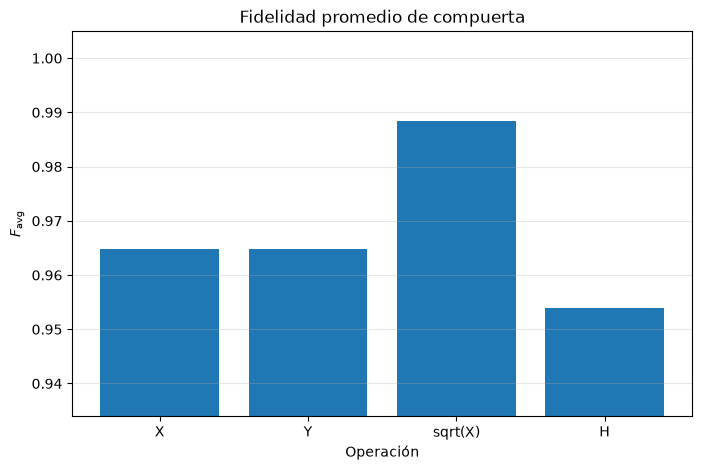

In [23]:
gate_names = list(average_fidelities.keys())
Favg_values = [average_fidelities[name] for name in gate_names]

plt.figure(figsize=(8, 5))
plt.bar(gate_names, Favg_values)
plt.ylabel(r"$F_{\mathrm{avg}}$")
plt.xlabel("Operación")
plt.title("Fidelidad promedio de compuerta")
plt.ylim(min(Favg_values) - 0.02, 1.005)
plt.grid(axis="y", alpha=0.3)
plt.show()

# 11. Interpretación física

El análisis compara dos descripciones.

## Aproximación semiclasica

$$
\alpha=|\alpha|e^{-i\phi}
$$

produce idealmente

$$
R_\phi(\theta),
\qquad
\theta=2g|\alpha|t.
$$

## Dinámica cuántica exacta

El estado coherente contiene una distribución de estados de Fock,

$$
|\alpha\rangle=\sum_nq_n|n\rangle,
$$

y cada uno evoluciona con una frecuencia distinta,

$$
\Omega_n=2g\sqrt{n+1}.
$$

Por ello pueden generarse correlaciones qubit--campo. Después de trazar el campo, el estado reducido puede satisfacer

$$
\operatorname{Tr}(\rho_q^2)<1,
$$

y dejar de coincidir exactamente con una rotación unitaria ideal.

La compuerta $Y$ prueba el control del **eje de rotación** mediante la fase $\phi$. La compuerta $\sqrt X$ prueba el control del **ángulo de rotación** mediante el tiempo. Hadamard constituye el primer ejemplo de una **operación compuesta** construida a partir de dos pulsos resonantes.

El propósito no es presentar estas matrices conocidas como nuevas, sino utilizarlas para caracterizar cuantitativamente hasta qué punto un estado coherente de amplitud finita puede actuar como recurso de control óptico en el modelo de Jaynes--Cummings resonante.

In [24]:
psi_field_check = qt.coherent(N, alpha_abs)

print("Norma del estado coherente =", psi_field_check.norm())
print("<n> numérico =", qt.expect(n_field, psi_field_check))
print("<n> teórico =", alpha_abs**2)

K_X = kraus_operators_single_pulse(
    phi=0.0,
    theta_target=np.pi
)

kraus_error = (
    check_kraus_completeness(K_X) - Iq
).norm()

print("Error de completez de Kraus para X =", kraus_error)

Norma del estado coherente = 0.9999999999999997
<n> numérico = 15.999999999989388
<n> teórico = 16
Error de completez de Kraus para X = 9.992007221626409e-16
